# 📉 Módulo 1 — O Modelo Ingênuo, o *Breakeven* de +28% e a Ilusão do Cupom de 30%

**Autor:** Dr. Silvio da Rosa Paula — Doutor em Economia Aplicada & Cientista de Dados

---

## 1. Contexto de Negócio e Anatomia da Margem Unitária

Uma rede de e-commerce de casa e decoração analisa se deve **escalar seu cupom promocional da Black Friday de `20%` para `30%`**. Para que essa decisão preserve ou aumente o lucro líquido, o ganho percentual de volume precisa superar a compressão da margem de contribuição unitária:

- **Ticket médio cheio ($P$):** `R$ 350,00`
- **Margem bruta antes do desconto ($m_0$):** `72,0%` (`CMV = R$ 98,00`)
- **Custo variável logístico e pagamento ($c_v$):** `R$ 22,00/pedido`

Logo, a margem de contribuição líquida por pedido $\text{CM}(d) = P(m_0 - d) - c_v$ vale:
$$\text{CM}(20\%) = 350(0{,}72 - 0{,}20) - 22 = \mathbf{\text{R\$ } 160{,}00} \qquad \text{vs.} \qquad \text{CM}(30\%) = 350(0{,}72 - 0{,}30) - 22 = \mathbf{\text{R\$ } 125{,}00}$$

O **lift mínimo de *breakeven*** exigido ao escalar de `20%` para `30%` é exatamente:
$$\Delta L_{\text{breakeven}} = \frac{\text{CM}(20\%)}{\text{CM}(30\%)} - 1 = \frac{160}{125} - 1 = \mathbf{+28{,}00\%}$$

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from IPython.display import display

from src.dgp import EconomicParams, save_or_load_panel, true_incremental_lift_20_to_30
from src.causal_models import fit_naive_model
from src.visuals import plot_01_naive_illusion_and_margin

PROJ_ROOT = Path(".").resolve()
df = save_or_load_panel(PROJ_ROOT / "data", seed=2025)
econ = EconomicParams()

print(f"Painel carregado          : {len(df):,} linhas ({df['unidade_id'].nunique()} unidades × {df['data'].nunique()} dias)")
print(f"Margem unitária em d=20%  : R$ {econ.unit_margin(0.20):,.2f}/pedido")
print(f"Margem unitária em d=30%  : R$ {econ.unit_margin(0.30):,.2f}/pedido")
print(f"Breakeven exato (20%->30%): +{econ.breakeven_lift_20_to_30*100:.2f}% de pedidos incrementais")
print(f"Lift Causal REAL global   : +{true_incremental_lift_20_to_30(None)*100:.2f}% (Móveis: +{true_incremental_lift_20_to_30('Moveis_Iluminacao')*100:.2f}% | Têxtil: +{true_incremental_lift_20_to_30('Textil_Objetos')*100:.2f}%)")
display(df.head())

Painel carregado          : 11,696 linhas (16 unidades × 731 dias)
Margem unitária em d=20%  : R$ 160.00/pedido
Margem unitária em d=30%  : R$ 125.00/pedido
Breakeven exato (20%->30%): +28.00% de pedidos incrementais
Lift Causal REAL global   : +10.27% (Móveis: +5.79% | Têxtil: +12.82%)


,data,unidade_id,regiao,categoria,categoria_label,tratada_bf24,is_bf23,is_bf24,is_black_friday,is_promo_sazonal,...,cupom,pedidos_organicos_y0,pedidos,pedidos_cf_20,pedidos_cf_30,margem_unitaria,receita_liquida,lucro_liquido,lucro_cf_20,lucro_cf_30
0,2023-01-01,Centro_DF__Moveis_Iluminacao,Centro_DF,Moveis_Iluminacao,Móveis & Iluminação,0,0,0,0,0,...,0.0,45.147,45.147,61.843,65.425,230.0,15801.33,10383.73,9894.90,8178.19
1,2023-01-01,Centro_DF__Textil_Objetos,Centro_DF,Textil_Objetos,Têxtil & Objetos,0,0,0,0,0,...,0.0,55.425,55.425,102.215,115.315,230.0,19398.70,12747.72,16354.44,14414.31
2,2023-01-01,MG_Capital__Moveis_Iluminacao,MG_Capital,Moveis_Iluminacao,Móveis & Iluminação,0,0,0,0,0,...,0.0,58.299,58.299,79.860,84.486,230.0,20404.73,13408.82,12777.57,10560.74
3,2023-01-01,MG_Capital__Textil_Objetos,MG_Capital,Textil_Objetos,Têxtil & Objetos,0,0,0,0,0,...,0.0,77.682,77.682,143.262,161.622,230.0,27188.67,17866.84,22921.93,20202.70
4,2023-01-01,NE_BA__Moveis_Iluminacao,NE_BA,Moveis_Iluminacao,Móveis & Iluminação,1,0,0,0,0,...,0.1,47.170,58.191,64.614,68.357,195.0,18330.30,11347.33,10338.29,8544.66


---
## 2. Por Que o Modelo Correlacional Ingênuo Falha?

Historicamente, o cupom agressivo de `30%` foi acionado sobretudo **durante os dias de pico da Black Friday**, quando o tráfego orgânico já dispara mais de `+50%` independentemente do cupom.

Se um analista ajustar uma regressão log-linear padrão controlando apenas unidade e dia da semana — **omitindo o choque orgânico de calendário da Black Friday**:
$$\ln(\text{Pedidos}_{it}) = \alpha_i + \delta_{\text{dow}(t)} + \beta \cdot \mathbb{I}(\text{Cupom}_{it} = 30\%) + u_{it} \quad \text{sobre } d_{it} \in \{20\%, 30\%\}$$
o estimador absorve o pico sazonal dentro de $\hat\beta$, criando uma **ilusão estatisticamente significante ($p < 10^{-39}$) acima do *breakeven* de `+28%`**!

,Indicador,Valor
0,Lift Estimado (Modelo Ingênuo),+40.19% (IC 95%: 33.4% a 47.4%)
1,p-valor do Modelo Ingênuo,2.83e-40 (altamente 'significativo'!)
2,Limiar de Breakeven (20% -> 30%),+28.00%
3,Lift Causal Verdadeiro (BF 2024),+10.26%
4,Ganho Projetado Ilusório (Regiões Tratadas),"+R$ 234,028.72"
5,Resultado REAL no Bolso (Erosão de Margem),"R$ -340,572.44"


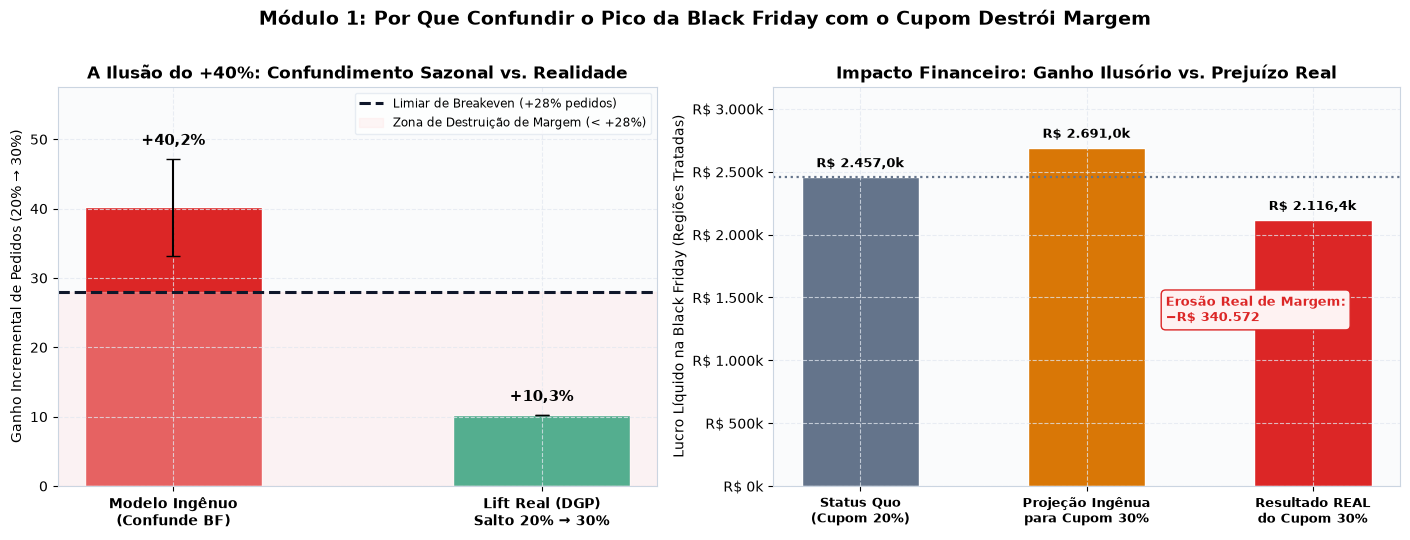

In [2]:
naive_res = fit_naive_model(df)

resumo_m1 = pd.DataFrame([
    {"Indicador": "Lift Estimado (Modelo Ingênuo)", "Valor": f"+{naive_res['naive_lift_pct']:.2f}% (IC 95%: {naive_res['ci_95_pct'][0]:.1f}% a {naive_res['ci_95_pct'][1]:.1f}%)"},
    {"Indicador": "p-valor do Modelo Ingênuo", "Valor": f"{naive_res['p_value']:.2e} (altamente 'significativo'!)"},
    {"Indicador": "Limiar de Breakeven (20% -> 30%)", "Valor": f"+{naive_res['breakeven_pct']:.2f}%"},
    {"Indicador": "Lift Causal Verdadeiro (BF 2024)", "Valor": f"+{naive_res['true_lift_pct']:.2f}%"},
    {"Indicador": "Ganho Projetado Ilusório (Regiões Tratadas)", "Valor": f"+R$ {naive_res['ganho_ilusorio_projetado_rs']:,.2f}"},
    {"Indicador": "Resultado REAL no Bolso (Erosão de Margem)", "Valor": f"R$ {naive_res['prejuizo_real_margem_rs']:,.2f}"},
])
display(resumo_m1)

fig1 = plot_01_naive_illusion_and_margin(naive_res, save_path=PROJ_ROOT / "img" / "01_ilusao_41pct_vs_breakeven.png")
plt.show()

### Conclusão Executiva do Módulo 1
- **Precisão aparente, decisão desastrosa:** o erro padrão pequeno (`±3,6%`) e o $p$-valor minúsculo ($2{,}8 \times 10^{-40}$) dão falsa segurança executiva para aprovar o cupom de `30%`, esperando ganhar **+R\$ 234 mil**.
- **Destruição real de margem:** como o ganho causal real do salto `20% → 30%` é de apenas **`+10,26%`** (muito abaixo dos `+28,00%` exigidos), a empresa amarga **−R\$ 340,6 mil de perda líquida** apenas nas 4 regiões tratadas (ou **−R\$ 677,6 mil** se escalado para toda a rede!).
- Nos próximos três notebooks (`02_bsts`, `03_controle_sintetico` e `04_did_heterogeneo`), veremos como **isolar o calendário do cupom** usando apenas dados observados.